# ♻️ EcoScan · Clasificación de residuos con modelos preentrenados
### IA Generativa para la Gestión Industrial · Proyecto grupal

**Problema:** separar mal los residuos contamina las cargas de reciclaje. Queremos que una persona suba la foto de un residuo y la app le diga de qué material es, con qué confianza, y le dé una recomendación.

Flujo: 📷 Foto → 🧠 Modelo preentrenado → 📊 Probabilidades → 💬 Gemini → ✅ Recomendación

| Enfoque | Librería | Idea |
|---|---|---|
| **1** · CLIP | Hugging Face `transformers` | Usar un modelo **tal cual**, sin entrenar (línea base) |
| **2** · EfficientNet-B0 | `timm` | **Transfer learning**: adaptar una CNN preentrenada |
| **3** · ResNet18 | `timm` | Otra CNN preentrenada, para comparar |

Este notebook **entrena y evalúa** los modelos. La app (`app.py`) solo carga el archivo `modelo.pt` que se exporta al final.

**Antes de empezar:** *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*.

> ⚠️ Prototipo educativo: el modelo sugiere el material, no certifica que un residuo sea reciclable.

## 0. Librerías

In [ ]:
!pip install -q timm                                  # timm: modelos preentrenados (EfficientNet, ResNet...)

import os, shutil, hashlib, json, zipfile, random     # manejo de archivos, carpetas y semillas
import numpy as np                                    # cálculo con matrices de números
import pandas as pd                                   # tablas
import matplotlib.pyplot as plt                       # gráficos e imágenes
import torch, timm                                    # PyTorch (motor de deep learning) y timm
from PIL import Image                                 # abrir imágenes
from torch.utils.data import DataLoader               # entrega las fotos en lotes
from torchvision.datasets import ImageFolder          # lee carpetas datos/<parte>/<clase>/
from sklearn.model_selection import train_test_split  # división estratificada
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from huggingface_hub import hf_hub_download           # descarga archivos desde Hugging Face

SEMILLA = 42                                          # semilla fija: resultados repetibles
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
DISP = "cuda" if torch.cuda.is_available() else "cpu" # usa la GPU si está activa
GPU = 0 if DISP == "cuda" else -1                     # formato que pide pipeline() de Hugging Face
print("Dispositivo:", DISP)

Dispositivo: cuda


## 1. Datos

| Aspecto | Detalle |
|---|---|
| Dataset | **TrashNet** · https://huggingface.co/datasets/garythung/trashnet |
| Autores | Gary Thung y Mindy Yang (proyecto Stanford CS229) · https://github.com/garythung/trashnet |
| Licencia | MIT |
| Cómo se obtuvo | Fotos de un objeto sobre cartulina blanca, tomadas con iPhone, con luz natural y/o de interior |
| Clases | `cardboard` (cartón), `glass` (vidrio), `metal`, `paper` (papel), `plastic` (plástico), `trash` (otros residuos) |

Usamos el archivo `dataset-resized.zip` (fotos de 512×384). No usamos `load_dataset()` porque el visor de Hugging Face muestra 5.054 filas, mientras la fuente original describe 2.527 fotos: con el ZIP usamos una sola versión de la colección.

In [ ]:
zip_path = hf_hub_download("garythung/trashnet", "dataset-resized.zip", repo_type="dataset")  # descarga (~43 MB)
with zipfile.ZipFile(zip_path) as z:
    z.extractall("/content/trashnet")                 # descomprime en /content/trashnet

CLASES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]   # orden alfabético = orden de ImageFolder
filas = []
for raiz, _, archivos in os.walk("/content/trashnet"):   # recorre todas las carpetas del ZIP
    clase = os.path.basename(raiz)                    # el nombre de la carpeta es la clase
    if clase not in CLASES or "__MACOSX" in raiz:     # ignora carpetas que no son clases (basura de macOS)
        continue
    for a in archivos:
        if a.lower().endswith(".jpg"):                # solo fotos
            ruta = os.path.join(raiz, a)
            huella = hashlib.md5(open(ruta, "rb").read()).hexdigest()   # "huella digital" del archivo
            filas.append({"ruta": ruta, "clase": clase, "huella": huella})
df = pd.DataFrame(filas)                              # una fila por foto
print("Fotos encontradas:", len(df))

dataset-resized.zip: reconstructing file:   0%|          |  0.00B / 42.8MB            

dataset-resized.zip: downloading bytes:           |  0.00B            

Fotos encontradas: 2527


**Limpieza:** si la misma foto aparece dos veces la dejamos una sola vez; si aparece con **dos etiquetas distintas** no sabemos cuál es la correcta y la eliminamos.

Fotos contradictorias eliminadas: 3
Fotos únicas usadas: 2521
cardboard : 403 imágenes
glass     : 498 imágenes
metal     : 409 imágenes
paper     : 594 imágenes
plastic   : 480 imágenes
trash     : 137 imágenes


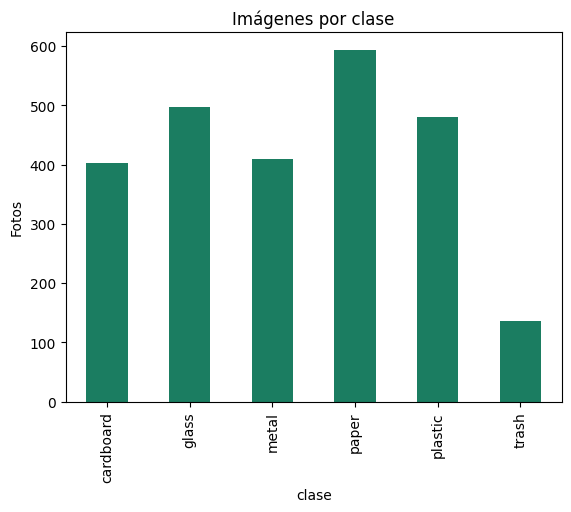

In [ ]:
etiquetas_por_foto = df.groupby("huella").clase.nunique()                 # cuántas clases distintas tiene cada foto
contradictorias = etiquetas_por_foto[etiquetas_por_foto > 1].index        # misma foto con distinta clase
df = df[~df.huella.isin(contradictorias)].drop_duplicates("huella")       # quita contradicciones y repetidas
print("Fotos contradictorias eliminadas:", len(contradictorias))
print("Fotos únicas usadas:", len(df))

for c in CLASES:                                                          # cuenta las fotos de cada clase
    print(f"{c:10s}: {(df.clase == c).sum()} imágenes")
df.clase.value_counts().reindex(CLASES).plot.bar(color="#1b7d61", title="Imágenes por clase")
plt.ylabel("Fotos"); plt.show()

**Desbalance:** `trash` tiene muchas menos fotos que `paper`. Por eso:
1. medimos **accuracy balanceada** (promedio del acierto de cada clase), no solo accuracy;
2. entrenamos con una **pérdida ponderada** que castiga más los errores en las clases chicas.

**Limitaciones de los datos:** una sola fuente, todas con fondo blanco y buena luz, un objeto por foto. En la vida real (basura sucia, fondos desordenados, varios objetos) el modelo probablemente rinda peor.

### División entrenamiento / validación / prueba (70 / 15 / 15)
Estratificada: cada parte mantiene la proporción de clases. **Entrenamiento** ajusta los pesos, **validación** sirve para elegir el modelo y **prueba** se usa una sola vez al final. Guardamos una carpeta por clase (`datos/train/<clase>`, `datos/val/<clase>`, `datos/test/<clase>`): el formato que entiende `ImageFolder`.

In [ ]:
train, resto = train_test_split(df, test_size=0.30, stratify=df.clase, random_state=SEMILLA)   # 70 % / 30 %
val, test = train_test_split(resto, test_size=0.50, stratify=resto.clase, random_state=SEMILLA) # 30 % → 15 % + 15 %

DATOS = "/content/datos"
shutil.rmtree(DATOS, ignore_errors=True)              # borra una copia anterior, si existe
for parte, fotos in [("train", train), ("val", val), ("test", test)]:
    for _, fila in fotos.iterrows():
        carpeta = f"{DATOS}/{parte}/{fila.clase}"
        os.makedirs(carpeta, exist_ok=True)           # crea la carpeta de la clase
        shutil.copy(fila.ruta, carpeta)               # copia la foto

conteos = {c: {p: len(os.listdir(f"{DATOS}/{p}/{c}")) for p in ["train", "val", "test"]} for c in CLASES}
for c in CLASES:
    print(f"{c:10s} train = {conteos[c]['train']:3d} | val = {conteos[c]['val']:3d} | test = {conteos[c]['test']:3d}")

cardboard  train = 282 | val =  60 | test =  61
glass      train = 348 | val =  75 | test =  75
metal      train = 286 | val =  61 | test =  62
paper      train = 416 | val =  89 | test =  89
plastic    train = 336 | val =  72 | test =  72
trash      train =  96 | val =  21 | test =  20


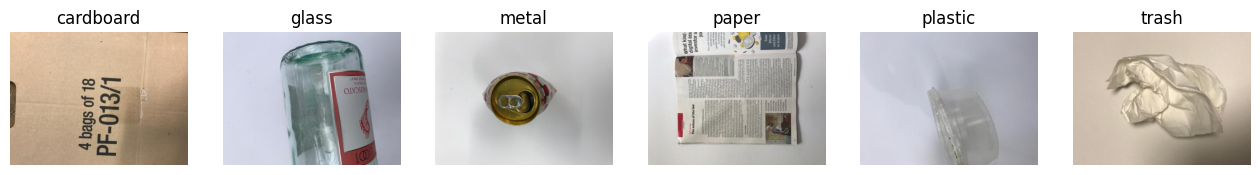

In [ ]:
fig, ejes = plt.subplots(1, 6, figsize=(16, 3))      # una foto de ejemplo por clase
for eje, c in zip(ejes, CLASES):
    eje.imshow(Image.open(train[train.clase == c].ruta.iloc[0])); eje.set_title(c); eje.axis("off")
plt.show()

**Evaluación común.** Para comparar en igualdad de condiciones, todos los enfoques se prueban con **las mismas fotos** y la **accuracy balanceada** (al azar = 1/6 ≈ 17 %). Cada modelo solo debe aportar una función `predecir(ruta) → clase`.

In [ ]:
RESULTADOS = {}                                       # aquí se guardan los puntajes de cada enfoque

def evaluar(nombre, predecir, parte="val"):
    fotos = [(f"{DATOS}/{parte}/{c}/{a}", c) for c in CLASES for a in sorted(os.listdir(f"{DATOS}/{parte}/{c}"))]
    reales = [c for _, c in fotos]                    # clase verdadera de cada foto
    preds  = [predecir(r) for r, _ in fotos]          # clase que predice el modelo
    puntaje = balanced_accuracy_score(reales, preds)
    if nombre:                                        # nombre=None → solo calcula (lo usamos al entrenar)
        RESULTADOS.setdefault(nombre, {})[f"acc_balanceada_{parte}"] = round(puntaje, 4)
        if parte == "test":
            RESULTADOS[nombre]["accuracy_test"] = round(accuracy_score(reales, preds), 4)
        print(f"{nombre} · {parte}: accuracy balanceada = {puntaje:.1%}")
    return puntaje, [r for r, _ in fotos], reales, preds

## 2. Enfoque 1 · CLIP sin entrenar (zero-shot)
CLIP acepta **las clases que tú le escribas**: compara la foto con cada frase y elige la más parecida. **No se entrena con nuestras fotos.** Si un modelo entrenado no le gana a esto, entrenar no valió la pena.

In [ ]:
from transformers import pipeline
clip = pipeline("zero-shot-image-classification", model="openai/clip-vit-base-patch32", device=GPU)
TEXTOS = {                                            # una frase en inglés por clase
    "cardboard": "a photo of cardboard",
    "glass":     "a photo of a glass bottle or jar",
    "metal":     "a photo of a metal can",
    "paper":     "a photo of paper",
    "plastic":   "a photo of a plastic bottle or container",
    "trash":     "a photo of garbage",
}
A_CLASE = {v: k for k, v in TEXTOS.items()}          # frase → clase

def predecir_clip(ruta):
    return A_CLASE[clip(ruta, candidate_labels=list(TEXTOS.values()))[0]["label"]]   # frase con mayor puntaje

evaluar("1 · CLIP (sin entrenar)", predecir_clip, "val");

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


1 · CLIP (sin entrenar) · val: accuracy balanceada = 63.0%


## 3. Enfoques 2 y 3 · Transfer learning con timm
Cargamos la red preentrenada en ImageNet, **cambiamos su salida a 6 clases** y la ajustamos con nuestras fotos, usando una tasa de aprendizaje pequeña (`1e-4`) para no "olvidar" lo que ya sabe.

Respecto de la pauta de clase agregamos lo que se pidió profundizar para el trabajo:
- **Aumento de datos** (`is_training=True`): recortes, volteos y cambios de color al azar, solo en entrenamiento.
- **Pérdida ponderada** por clase, por el desbalance.
- **Más épocas** con **parada temprana**: si la validación no mejora en 3 épocas se detiene y se recupera la mejor época (igual que `EarlyStopping` de la Pauta 1).

Las dos redes se entrenan con **la misma función** `entrenar()`.

In [ ]:
def predecir_timm(modelo, prep, ruta):
    with torch.no_grad():                             # sin calcular gradientes: solo predecir
        x = prep(Image.open(ruta).convert("RGB")).unsqueeze(0).to(DISP)   # foto → tensor (1 foto en el lote)
        return CLASES[modelo(x).argmax(1).item()]     # clase con mayor puntaje


def entrenar(nombre, epocas=8, paciencia=3):
    torch.manual_seed(SEMILLA)                        # misma inicialización para ambos modelos
    modelo = timm.create_model(nombre, pretrained=True, num_classes=6).to(DISP)   # red ImageNet con salida de 6 clases
    config = timm.data.resolve_model_data_config(modelo)                           # tamaño y normalización del modelo
    prep_train = timm.data.create_transform(**config, is_training=True)           # con aumento de datos
    prep = timm.data.create_transform(**config)                                    # sin aumento (val, test y app)
    dl = DataLoader(ImageFolder(f"{DATOS}/train", transform=prep_train), batch_size=32, shuffle=True, num_workers=2)

    n = torch.tensor([conteos[c]["train"] for c in CLASES], dtype=torch.float32)
    pesos = (n.sum() / (6 * n)).to(DISP)              # clase con menos fotos → peso mayor
    opt, perdida = torch.optim.AdamW(modelo.parameters(), lr=1e-4), torch.nn.CrossEntropyLoss(weight=pesos)

    mejor, sin_mejora, historial = -1, 0, []
    for epoca in range(epocas):
        modelo.train()                                # modo entrenamiento
        for x, y in dl:
            opt.zero_grad(); l = perdida(modelo(x.to(DISP)), y.to(DISP)); l.backward(); opt.step()
        modelo.eval()                                 # modo predicción
        puntaje = evaluar(None, lambda ruta: predecir_timm(modelo, prep, ruta), "val")[0]
        historial.append(puntaje)
        print(f"{nombre} | época {epoca + 1} | pérdida {l.item():.3f} | acc. balanceada val {puntaje:.1%}")
        if puntaje > mejor:                           # mejoró: guardamos una copia de estos pesos
            mejor, sin_mejora = puntaje, 0
            mejores_pesos = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:               # parada temprana
                print("Parada temprana: la validación dejó de mejorar"); break
    modelo.load_state_dict(mejores_pesos)             # recupera la mejor época
    modelo.eval()
    RESULTADOS[nombre] = {"acc_balanceada_val": round(mejor, 4)}
    return {"modelo": modelo, "prep": prep, "config": config, "historial": historial}

In [ ]:
MODELOS = {nombre: entrenar(nombre) for nombre in ["efficientnet_b0", "resnet18"]}   # enfoques 2 y 3

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

efficientnet_b0 | época 1 | pérdida 0.746 | acc. balanceada val 64.3%
efficientnet_b0 | época 2 | pérdida 0.599 | acc. balanceada val 72.0%
efficientnet_b0 | época 3 | pérdida 0.985 | acc. balanceada val 73.0%
efficientnet_b0 | época 4 | pérdida 0.053 | acc. balanceada val 77.5%
efficientnet_b0 | época 5 | pérdida 0.189 | acc. balanceada val 79.9%
efficientnet_b0 | época 6 | pérdida 0.662 | acc. balanceada val 81.6%
efficientnet_b0 | época 7 | pérdida 1.877 | acc. balanceada val 82.2%
efficientnet_b0 | época 8 | pérdida 2.836 | acc. balanceada val 84.9%


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet18 | época 1 | pérdida 1.696 | acc. balanceada val 43.9%
resnet18 | época 2 | pérdida 1.752 | acc. balanceada val 55.9%
resnet18 | época 3 | pérdida 1.168 | acc. balanceada val 60.1%
resnet18 | época 4 | pérdida 1.352 | acc. balanceada val 65.7%
resnet18 | época 5 | pérdida 0.872 | acc. balanceada val 68.5%
resnet18 | época 6 | pérdida 1.553 | acc. balanceada val 71.5%
resnet18 | época 7 | pérdida 0.905 | acc. balanceada val 73.9%
resnet18 | época 8 | pérdida 0.937 | acc. balanceada val 75.6%


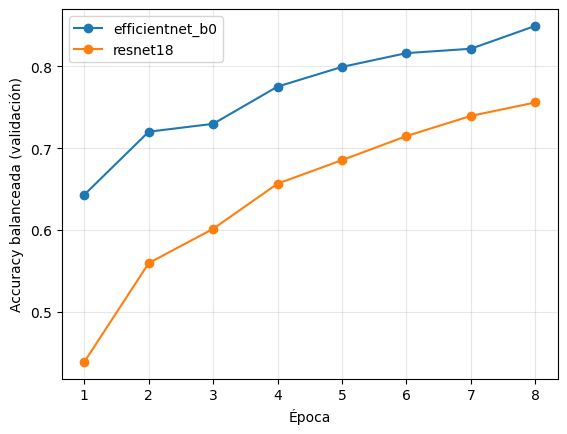

In [ ]:
for nombre, m in MODELOS.items():                     # curva de validación por época
    plt.plot(range(1, len(m["historial"]) + 1), m["historial"], marker="o", label=nombre)
plt.xlabel("Época"); plt.ylabel("Accuracy balanceada (validación)"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 4. Elección del modelo y evaluación en prueba
**Elegimos con validación** (antes de mirar prueba). Después evaluamos los tres enfoques en prueba con la misma función `evaluar`.

Modelo elegido por validación: efficientnet_b0 

1 · CLIP (sin entrenar) · test: accuracy balanceada = 65.3%
efficientnet_b0 · test: accuracy balanceada = 82.4%
resnet18 · test: accuracy balanceada = 78.2%


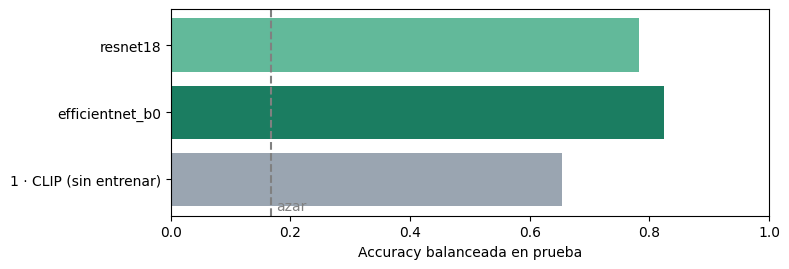

,acc_balanceada_val,acc_balanceada_test,accuracy_test
1 · CLIP (sin entrenar),0.6304,0.6534,0.7071
efficientnet_b0,0.8495,0.8243,0.8443
resnet18,0.7559,0.7823,0.7889


In [ ]:
elegido = max(MODELOS, key=lambda n: RESULTADOS[n]["acc_balanceada_val"])   # mejor en validación
print("Modelo elegido por validación:", elegido, "\n")

evaluar("1 · CLIP (sin entrenar)", predecir_clip, "test")
for nombre, m in MODELOS.items():
    _, rutas_test, y_real, y_pred = evaluar(nombre, lambda ruta: predecir_timm(m["modelo"], m["prep"], ruta), "test")
    if nombre == elegido:                             # guardamos las predicciones del elegido
        rutas, reales, preds = rutas_test, y_real, y_pred

tabla = pd.DataFrame(RESULTADOS).T                    # una fila por enfoque
plt.figure(figsize=(8, 2.8))
plt.barh(tabla.index, tabla["acc_balanceada_test"], color=["#9aa5b1", "#1b7d61", "#62b99a"])
plt.axvline(1/6, ls="--", color="gray"); plt.text(1/6 + .01, -0.45, "azar", color="gray")
plt.xlim(0, 1); plt.xlabel("Accuracy balanceada en prueba"); plt.tight_layout(); plt.show()
tabla

              precision    recall  f1-score   support

   cardboard      0.918     0.918     0.918        61
       glass      0.938     0.813     0.871        75
       metal      0.784     0.935     0.853        62
       paper      0.837     0.865     0.851        89
     plastic      0.846     0.764     0.803        72
       trash      0.591     0.650     0.619        20

    accuracy                          0.844       379
   macro avg      0.819     0.824     0.819       379
weighted avg      0.850     0.844     0.845       379



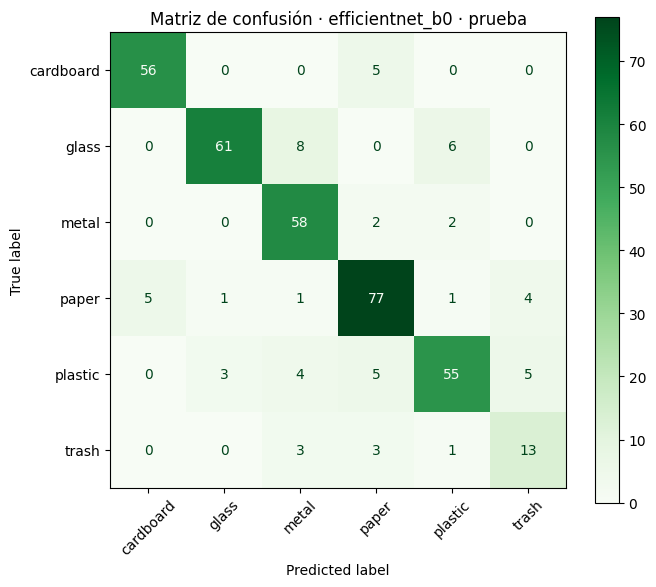

In [ ]:
print(classification_report(reales, preds, labels=CLASES, digits=3))   # precision, recall y f1 por clase

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(reales, preds, labels=CLASES), display_labels=CLASES).plot(
    ax=ax, cmap="Greens", xticks_rotation=45)        # matriz de confusión
ax.set_title(f"Matriz de confusión · {elegido} · prueba"); plt.tight_layout()
os.makedirs("/content/modelo", exist_ok=True)
plt.savefig("/content/modelo/matriz_confusion.png", dpi=150); plt.show()   # la app muestra esta imagen

## 5. ¿Cuál es el error más costoso?
El peor error es que un residuo **no reciclable** (`trash`) se clasifique como un material reciclable (vidrio, metal, papel…): la persona lo echa al contenedor equivocado y **contamina toda la carga**, que puede terminar en el relleno sanitario. Confundir dos materiales reciclables entre sí (ej. vidrio ↔ plástico) también cuesta, pero se puede corregir en la planta de separación.

Miramos la fila `trash` de la matriz y algunos errores:

De 20 fotos de 'trash', el modelo acertó 13.
  3 se clasificaron como metal
  3 se clasificaron como paper
  1 se clasificaron como plastic
Errores: 59 de 379


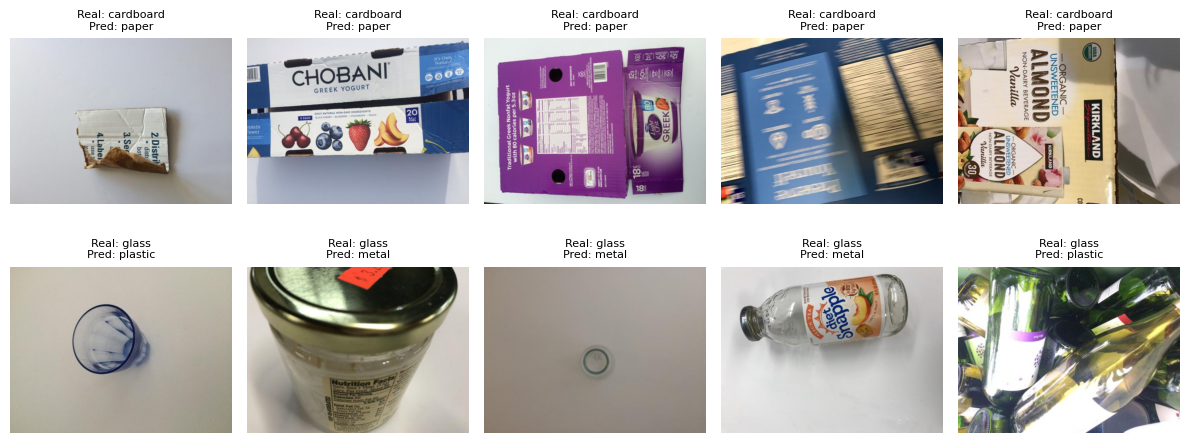

In [ ]:
fila = confusion_matrix(reales, preds, labels=CLASES)[CLASES.index("trash")]   # fila de 'trash'
print(f"De {fila.sum()} fotos de 'trash', el modelo acertó {fila[CLASES.index('trash')]}.")
for c, n in zip(CLASES, fila):
    if c != "trash" and n > 0:
        print(f"  {n} se clasificaron como {c}")

errores = [i for i in range(len(reales)) if preds[i] != reales[i]]   # posiciones donde se equivocó
print("Errores:", len(errores), "de", len(reales))
plt.figure(figsize=(12, 5))
for k, i in enumerate(errores[:10]):                  # muestra los primeros 10 errores
    plt.subplot(2, 5, k + 1)
    plt.imshow(Image.open(rutas[i]))
    plt.title(f"Real: {reales[i]}\nPred: {preds[i]}", fontsize=8); plt.axis("off")
plt.tight_layout(); plt.show()

## 6. ¿Tiene sentido pedir revisión humana bajo 70 % de confianza?
La app avisa cuando la confianza es menor a 70 %. Revisamos en prueba si las predicciones con baja confianza realmente fallan más.

In [ ]:
m = MODELOS[elegido]
def confianza(ruta):                                  # probabilidad de la clase predicha
    with torch.no_grad():
        x = m["prep"](Image.open(ruta).convert("RGB")).unsqueeze(0).to(DISP)
        return m["modelo"](x).softmax(1).max().item()

conf = np.array([confianza(r) for r in rutas])
acierto = np.array(preds) == np.array(reales)
print(f"Confianza ≥ 70 %: {(conf >= .7).mean():.0%} de las fotos · aciertan el {acierto[conf >= .7].mean():.1%}")
print(f"Confianza < 70 %: {(conf < .7).mean():.0%} de las fotos · aciertan el {acierto[conf < .7].mean():.1%}")

Confianza ≥ 70 %: 89% de las fotos · aciertan el 89.9%
Confianza < 70 %: 11% de las fotos · aciertan el 41.9%


## 7. Exportar el modelo para la app
Guardamos pesos + clases + preprocesamiento en un solo archivo, las métricas que muestra la app y 5 fotos de **prueba** como ejemplos.

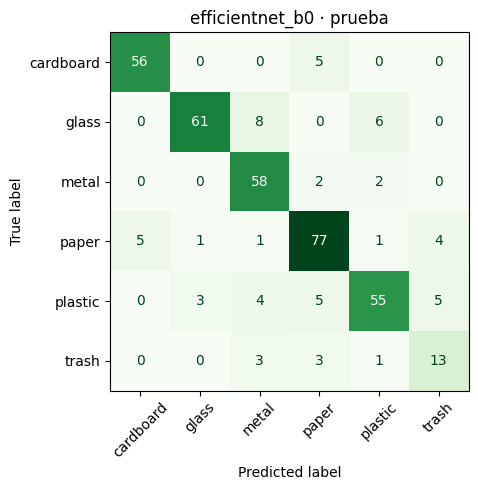

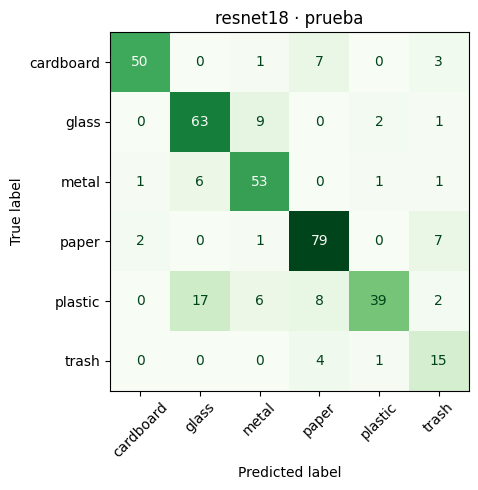

Contenido del ZIP: ['modelo/matriz_efficientnet_b0.png', 'modelo/matriz_resnet18.png', 'modelo/metricas.json', 'modelo/modelo.pt', 'ejemplos/cardboard.jpg', 'ejemplos/glass.jpg', 'ejemplos/metal.jpg', 'ejemplos/paper.jpg', 'ejemplos/plastic.jpg']
{
  "modelo_elegido": "efficientnet_b0",
  "n_prueba": 379,
  "accuracy": 0.8443,
  "accuracy_balanceada": 0.8243,
  "f1_macro": 0.8192
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
from google.colab import files                        # para descargar el ZIP
os.makedirs("/content/modelo", exist_ok=True)
os.makedirs("/content/ejemplos", exist_ok=True)

for modelo_i in MODELOS.values():                     # asegura que los modelos estén en la GPU
    modelo_i["modelo"].to(DISP).eval()

# 1) Una matriz de confusión por modelo (en prueba)
if os.path.exists("/content/modelo/matriz_confusion.png"):
    os.remove("/content/modelo/matriz_confusion.png") # nombre antiguo: lo reemplazan las de abajo
for nombre, modelo_i in MODELOS.items():
    if os.path.exists(f"/content/modelo/matriz_{nombre}.png"):
        continue                                      # ya se guardó en la sección 4
    _, _, y_real, y_pred = evaluar(None, lambda ruta: predecir_timm(modelo_i["modelo"], modelo_i["prep"], ruta), "test")
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred, labels=CLASES), display_labels=CLASES).plot(
        ax=ax, cmap="Greens", xticks_rotation=45, colorbar=False)
    ax.set_title(f"{nombre} · prueba"); plt.tight_layout()
    plt.savefig(f"/content/modelo/matriz_{nombre}.png", dpi=150); plt.show()

# 2) Modelo elegido: pesos + clases + preprocesamiento en un solo archivo
m = MODELOS[elegido]
torch.save({"architecture": elegido,                  # nombre de la red
            "classes": CLASES,                        # orden de las clases
            "state_dict": {k: v.cpu() for k, v in m["modelo"].state_dict().items()},   # pesos entrenados
            "data_config": m["config"]},              # tamaño y normalización
           "/content/modelo/modelo.pt")

# 3) Métricas que muestra la app (pestaña Desempeño)
metricas = {"modelo_elegido": elegido, "n_prueba": len(reales),
            "accuracy": round(accuracy_score(reales, preds), 4),
            "accuracy_balanceada": round(balanced_accuracy_score(reales, preds), 4),
            "f1_macro": round(f1_score(reales, preds, average="macro"), 4),
            "comparacion": [{"enfoque": n, **v} for n, v in RESULTADOS.items()],
            "conteos": conteos}
json.dump(metricas, open("/content/modelo/metricas.json", "w"), indent=2, ensure_ascii=False)

# 4) Un ejemplo de prueba por clase
for c in CLASES[:5]:
    shutil.copy(test[test.clase == c].ruta.iloc[0], f"/content/ejemplos/{c}.jpg")

# 5) Todo en un solo ZIP y descarga
with zipfile.ZipFile("/content/para_la_app.zip", "w") as z:
    for carpeta in ["modelo", "ejemplos"]:
        for archivo in sorted(os.listdir(f"/content/{carpeta}")):
            z.write(f"/content/{carpeta}/{archivo}", f"{carpeta}/{archivo}")
print("Contenido del ZIP:", zipfile.ZipFile("/content/para_la_app.zip").namelist())
print(json.dumps({k: v for k, v in metricas.items() if k not in ("conteos", "comparacion")}, indent=2))
files.download("/content/para_la_app.zip")           # si no se descarga: panel 📁 → clic derecho → Descargar

## 8. Conclusiones
*(Completar con los números obtenidos arriba.)*
- ¿Cuánto mejoró el transfer learning respecto de CLIP sin entrenar?
- ¿Por qué elegimos el modelo que elegimos?
- ¿Qué pasa con la clase `trash` y qué riesgo implica?
- ¿Qué mejoraríamos? (fotos reales con fondos sucios, más fotos de `trash`, validar fuera de TrashNet)